In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "part_c_text").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent

PART_C_DIR = PROJECT_ROOT / "part_c_text"
assert (PART_C_DIR / "arabic_cleaner.py").exists(), f"arabic_cleaner.py not found in {PART_C_DIR}"

if str(PART_C_DIR) not in sys.path:
    sys.path.insert(0, str(PART_C_DIR))

from arabic_cleaner import clean_arabic_text

print("Project root:", PROJECT_ROOT)

Project root: F:\Study\Year_3\Machine Learning\Hushhhhh-machine-is-learning


In [2]:
USE_MEMBER1_SPLITS = False
SPLITS_DIR = PROJECT_ROOT / "part_c_text" / "data"
RAW_DATA_DIR = Path(r"F:\Study\Year_3\Machine Learning\Dataset_Text")
MAX_SAMPLES_PER_CLASS = 2000


def load_raw_sanad(data_dir, max_per_class=2000, seed=42):
    class_folders = sorted([
        p for p in data_dir.rglob("*")
        if p.is_dir() and any(p.glob("*.txt"))
    ])
    if not class_folders:
        raise FileNotFoundError(f"No folders with .txt files found in: {data_dir}")

    rng = np.random.default_rng(seed)
    records = []
    stats = {"discovered": 0, "loaded": 0, "empty": 0, "decode_errors": 0}

    for folder in class_folders:
        category = folder.name
        txt_files = sorted(folder.glob("*.txt"))
        stats["discovered"] += len(txt_files)

        if max_per_class and len(txt_files) > max_per_class:
            idx = rng.choice(len(txt_files), size=max_per_class, replace=False)
            txt_files = [txt_files[i] for i in idx]

        for fp in txt_files:
            try:
                content = fp.read_text(encoding="utf-8").strip()
                if not content:
                    stats["empty"] += 1
                    continue
                records.append({"text": content, "category": category})
                stats["loaded"] += 1
            except UnicodeDecodeError:
                stats["decode_errors"] += 1

    print("File loading summary:", stats)
    return pd.DataFrame(records)


if USE_MEMBER1_SPLITS:
    train_df = pd.read_csv(SPLITS_DIR / "train.csv")
    val_df = pd.read_csv(SPLITS_DIR / "val.csv")
    test_df = pd.read_csv(SPLITS_DIR / "test.csv")

    for name, df in [("train", train_df), ("val", val_df), ("test", test_df)]:
        assert {"text", "category"}.issubset(df.columns), f"Missing required columns in {name}.csv"
        df.dropna(subset=["text", "category"], inplace=True)

    print("Loaded pre-split datasets from Member 1.")
else:
    full_df = load_raw_sanad(RAW_DATA_DIR, max_per_class=MAX_SAMPLES_PER_CLASS, seed=RANDOM_STATE)
    full_df.dropna(subset=["text", "category"], inplace=True)

    # remove texts that appear under multiple conflicting categories
    label_counts = full_df.groupby("text")["category"].nunique()
    conflicting_texts = label_counts[label_counts > 1].index
    if len(conflicting_texts) > 0:
        print(f"Removed {len(conflicting_texts)} conflicting duplicate texts across classes.")
        full_df = full_df[~full_df["text"].isin(conflicting_texts)]

    # remove exact duplicates within the same category
    before_dedup = len(full_df)
    full_df.drop_duplicates(subset=["text", "category"], inplace=True)
    print(f"Removed {before_dedup - len(full_df)} exact duplicate articles.")

    min_class_count = full_df["category"].value_counts().min()
    assert min_class_count >= 10, f"Class count too small for stratified split: {min_class_count}"

    train_df, temp_df = train_test_split(
        full_df,
        test_size=0.30,
        stratify=full_df["category"],
        random_state=RANDOM_STATE,
    )
    val_df, test_df = train_test_split(
        temp_df,
        test_size=0.50,
        stratify=temp_df["category"],
        random_state=RANDOM_STATE,
    )
    print("Loaded and split raw SANAD sample (70% / 15% / 15%).")

X_train, y_train = train_df["text"].values, train_df["category"].values
X_val, y_val = val_df["text"].values, val_df["category"].values
X_test, y_test = test_df["text"].values, test_df["category"].values

print(f"Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")
print("\nTrain class distribution:")
print(train_df["category"].value_counts())

File loading summary: {'discovered': 45500, 'loaded': 14000, 'empty': 0, 'decode_errors': 0}


C:\Users\PC\AppData\Local\Temp\ipykernel_22092\2661662367.py:55: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  full_df.dropna(subset=["text", "category"], inplace=True)
C:\Users\PC\AppData\Local\Temp\ipykernel_22092\2661662367.py:66: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  full_df.drop_duplicates(subset=["text", "category"], inplace=True)


Removed 4 exact duplicate articles.
Loaded and split raw SANAD sample (70% / 15% / 15%).
Train: 9797 | Val: 2099 | Test: 2100

Train class distribution:
category
Politics    1400
Tech        1400
Finance     1400
Medical     1400
Sports      1400
Culture     1399
Religion    1398
Name: count, dtype: int64


In [ ]:
train_set, val_set, test_set = set(X_train), set(X_val), set(X_test)
assert len(train_set & val_set) == 0, "Data leakage: duplicate texts between train and val!"
assert len(train_set & test_set) == 0, "Data leakage: duplicate texts between train and test!"
assert len(val_set & test_set) == 0, "Data leakage: duplicate texts between val and test!"


def build_text_pipeline(vectorizer_type="tfidf", ngram_range=(1, 1), max_features=20000, classifier=None):
    if vectorizer_type == "bow":
        vectorizer = CountVectorizer(
            preprocessor=clean_arabic_text,
            ngram_range=ngram_range,
            max_features=max_features,
        )
    elif vectorizer_type == "tfidf":
        vectorizer = TfidfVectorizer(
            preprocessor=clean_arabic_text,
            ngram_range=ngram_range,
            max_features=max_features,
        )
    else:
        raise ValueError("vectorizer_type must be 'bow' or 'tfidf'")

    if classifier is None:
        classifier = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)

    return Pipeline([
        ("vectorizer", vectorizer),
        ("clf", classifier),
    ])

In [4]:
baseline_pipe = build_text_pipeline(
    vectorizer_type="tfidf",
    ngram_range=(1, 1),
    max_features=20000,
    classifier=LogisticRegression(C=1.0, max_iter=1000, random_state=RANDOM_STATE),
)

baseline_pipe.fit(X_train, y_train)
baseline_preds = baseline_pipe.predict(X_val)

baseline_acc = accuracy_score(y_val, baseline_preds)
baseline_f1 = f1_score(y_val, baseline_preds, average="macro")
retained_vocab = len(baseline_pipe.named_steps["vectorizer"].vocabulary_)

print(f"Baseline Val Accuracy : {baseline_acc:.4f}")
print(f"Baseline Val Macro F1 : {baseline_f1:.4f}")
print(f"Retained Vocab Size   : {retained_vocab}")

Baseline Val Accuracy : 0.9667
Baseline Val Macro F1 : 0.9666
Retained Vocab Size   : 20000


In [5]:
import time
from sklearn.svm import LinearSVC

vec_configs = [
    {"name": "BoW (1, 1)", "type": "bow", "ngram": (1, 1), "max_feat": 20000},
    {"name": "BoW (1, 2)", "type": "bow", "ngram": (1, 2), "max_feat": 30000},
    {"name": "TF-IDF (1, 1)", "type": "tfidf", "ngram": (1, 1), "max_feat": 20000},
    {"name": "TF-IDF (1, 2)", "type": "tfidf", "ngram": (1, 2), "max_feat": 30000},
]

models_to_test = [
    ("Logistic Regression", lambda: LogisticRegression(C=1.0, max_iter=1000, random_state=RANDOM_STATE)),
    ("LinearSVC", lambda: LinearSVC(C=1.0, random_state=RANDOM_STATE)),
]

vec_exp_rows = []
for model_name, model_fn in models_to_test:
    for cfg in vec_configs:
        t0 = time.time()
        pipe = build_text_pipeline(
            vectorizer_type=cfg["type"],
            ngram_range=cfg["ngram"],
            max_features=cfg["max_feat"],
            classifier=model_fn(),
        )
        pipe.fit(X_train, y_train)
        elapsed = time.time() - t0

        preds = pipe.predict(X_val)
        vec_exp_rows.append({
            "Model": model_name,
            "Representation": cfg["name"],
            "vec_type": cfg["type"],
            "ngram": cfg["ngram"],
            "max_feat": cfg["max_feat"],
            "Val Accuracy": round(accuracy_score(y_val, preds), 4),
            "Val Macro F1": round(f1_score(y_val, preds, average="macro"), 4),
            "Time (s)": round(elapsed, 2),
        })

vec_comparison_df = pd.DataFrame(vec_exp_rows)
display(vec_comparison_df[["Model", "Representation", "Val Accuracy", "Val Macro F1", "Time (s)"]])

# pick best vectorizer independently for each model
lr_subset = vec_comparison_df[vec_comparison_df["Model"] == "Logistic Regression"]
best_lr_vec = lr_subset.loc[lr_subset["Val Macro F1"].idxmax()]

svc_subset = vec_comparison_df[vec_comparison_df["Model"] == "LinearSVC"]
best_svc_vec = svc_subset.loc[svc_subset["Val Macro F1"].idxmax()]

print(f"Best Vectorizer for Logistic Regression : {best_lr_vec['Representation']} (F1 = {best_lr_vec['Val Macro F1']})")
print(f"Best Vectorizer for LinearSVC           : {best_svc_vec['Representation']} (F1 = {best_svc_vec['Val Macro F1']})")

,Model,Representation,Val Accuracy,Val Macro F1,Time (s)
0,Logistic Regression,"BoW (1, 1)",0.9662,0.9662,4.13
1,Logistic Regression,"BoW (1, 2)",0.9643,0.9643,11.69
2,Logistic Regression,"TF-IDF (1, 1)",0.9667,0.9666,4.14
3,Logistic Regression,"TF-IDF (1, 2)",0.9681,0.9681,11.38
4,LinearSVC,"BoW (1, 1)",0.9652,0.9652,3.02
5,LinearSVC,"BoW (1, 2)",0.9662,0.9662,10.26
6,LinearSVC,"TF-IDF (1, 1)",0.9705,0.9704,3.08
7,LinearSVC,"TF-IDF (1, 2)",0.9705,0.9705,12.08


Best Vectorizer for Logistic Regression : TF-IDF (1, 2) (F1 = 0.9681)
Best Vectorizer for LinearSVC           : TF-IDF (1, 2) (F1 = 0.9705)


In [ ]:
tuning_rows = []

best_lr_pipeline, best_lr_f1, best_lr_acc, best_lr_time, best_lr_c = None, -1.0, -1.0, float("inf"), None
for c in [0.05, 0.1, 0.5, 1.0, 2.0, 5.0]:
    t0 = time.time()
    pipe = build_text_pipeline(
        vectorizer_type=best_lr_vec["vec_type"],
        ngram_range=best_lr_vec["ngram"],
        max_features=int(best_lr_vec["max_feat"]),
        classifier=LogisticRegression(C=c, max_iter=1000, random_state=RANDOM_STATE),
    )
    pipe.fit(X_train, y_train)
    elapsed = time.time() - t0

    preds = pipe.predict(X_val)
    acc = accuracy_score(y_val, preds)
    f1 = f1_score(y_val, preds, average="macro")
    tuning_rows.append({
        "Model": "Logistic Regression",
        "Vectorizer": best_lr_vec["Representation"],
        "C": c,
        "Val Accuracy": round(acc, 4),
        "Val Macro F1": round(f1, 4),
        "Time (s)": round(elapsed, 2),
    })
    if (f1, acc) > (best_lr_f1, best_lr_acc):
        best_lr_f1, best_lr_acc, best_lr_time = f1, acc, elapsed
        best_lr_pipeline, best_lr_c = pipe, c

best_svc_pipeline, best_svc_f1, best_svc_acc, best_svc_time, best_svc_c = None, -1.0, -1.0, float("inf"), None
for c in [0.01, 0.05, 0.1, 0.5, 1.0, 2.0, 5.0]:
    t0 = time.time()
    pipe = build_text_pipeline(
        vectorizer_type=best_svc_vec["vec_type"],
        ngram_range=best_svc_vec["ngram"],
        max_features=int(best_svc_vec["max_feat"]),
        classifier=LinearSVC(C=c, max_iter=2000, random_state=RANDOM_STATE),
    )
    pipe.fit(X_train, y_train)
    elapsed = time.time() - t0

    preds = pipe.predict(X_val)
    acc = accuracy_score(y_val, preds)
    f1 = f1_score(y_val, preds, average="macro")
    tuning_rows.append({
        "Model": "LinearSVC",
        "Vectorizer": best_svc_vec["Representation"],
        "C": c,
        "Val Accuracy": round(acc, 4),
        "Val Macro F1": round(f1, 4),
        "Time (s)": round(elapsed, 2),
    })
    if (f1, acc) > (best_svc_f1, best_svc_acc):
        best_svc_f1, best_svc_acc, best_svc_time = f1, acc, elapsed
        best_svc_pipeline, best_svc_c = pipe, c

tuning_df = pd.DataFrame(tuning_rows)
display(tuning_df)

lr_label = f"Logistic Regression ({best_lr_vec['Representation']}, C={best_lr_c})"
svc_label = f"LinearSVC ({best_svc_vec['Representation']}, C={best_svc_c})"

val_summary_df = pd.DataFrame([
    {"Model": lr_label, "Val Accuracy": round(best_lr_acc, 4), "Val Macro F1": round(best_lr_f1, 4), "Train Time (s)": round(best_lr_time, 2)},
    {"Model": svc_label, "Val Accuracy": round(best_svc_acc, 4), "Val Macro F1": round(best_svc_f1, 4), "Train Time (s)": round(best_svc_time, 2)},
])
display(val_summary_df)

if (best_svc_f1, best_svc_acc) >= (best_lr_f1, best_lr_acc):
    winner_key = "svc"
    overall_best_pipeline = best_svc_pipeline
    overall_best_name = svc_label
else:
    winner_key = "lr"
    overall_best_pipeline = best_lr_pipeline
    overall_best_name = lr_label

print("Selected champion model:", overall_best_name)

,Model,Vectorizer,C,Val Accuracy,Val Macro F1,Time (s)
0,Logistic Regression,"TF-IDF (1, 2)",0.05,0.9443,0.9439,10.86
1,Logistic Regression,"TF-IDF (1, 2)",0.10,0.9528,0.9527,10.77
2,Logistic Regression,"TF-IDF (1, 2)",0.50,0.9667,0.9666,11.35
3,Logistic Regression,"TF-IDF (1, 2)",1.00,0.9681,0.9681,11.88
4,Logistic Regression,"TF-IDF (1, 2)",2.00,0.9690,0.9690,12.13
5,Logistic Regression,"TF-IDF (1, 2)",5.00,0.9690,0.9690,12.41
6,LinearSVC,"TF-IDF (1, 2)",0.01,0.9609,0.9608,10.60
7,LinearSVC,"TF-IDF (1, 2)",0.05,0.9676,0.9676,10.45
8,LinearSVC,"TF-IDF (1, 2)",0.10,0.9690,0.9690,11.53
9,LinearSVC,"TF-IDF (1, 2)",0.50,0.9705,0.9705,10.34


,Model,Val Accuracy,Val Macro F1,Train Time (s)
0,"Logistic Regression (TF-IDF (1, 2), C=5.0)",0.9690,0.9690,12.41
1,"LinearSVC (TF-IDF (1, 2), C=5.0)",0.9705,0.9705,10.68


Selected champion model: LinearSVC (TF-IDF (1, 2), C=5.0)


,Model,Test Accuracy,Test Macro F1,Test Weighted F1
0,"Logistic Regression (TF-IDF (1, 2), C=5.0)",0.9738,0.9738,0.9738
1,"LinearSVC (TF-IDF (1, 2), C=5.0) [Champion]",0.9762,0.9762,0.9762



Classification Report — Logistic Regression (TF-IDF (1, 2), C=5.0):
              precision    recall  f1-score   support

     Culture     0.9607    0.9767    0.9686       300
     Finance     0.9897    0.9600    0.9746       300
     Medical     0.9798    0.9700    0.9749       300
    Politics     0.9612    0.9900    0.9754       300
    Religion     0.9794    0.9500    0.9645       300
      Sports     1.0000    0.9867    0.9933       300
        Tech     0.9486    0.9833    0.9656       300

    accuracy                         0.9738      2100
   macro avg     0.9742    0.9738    0.9738      2100
weighted avg     0.9742    0.9738    0.9738      2100


Classification Report — LinearSVC (TF-IDF (1, 2), C=5.0):
              precision    recall  f1-score   support

     Culture     0.9639    0.9800    0.9719       300
     Finance     0.9898    0.9733    0.9815       300
     Medical     0.9733    0.9733    0.9733       300
    Politics     0.9672    0.9833    0.9752       300
    

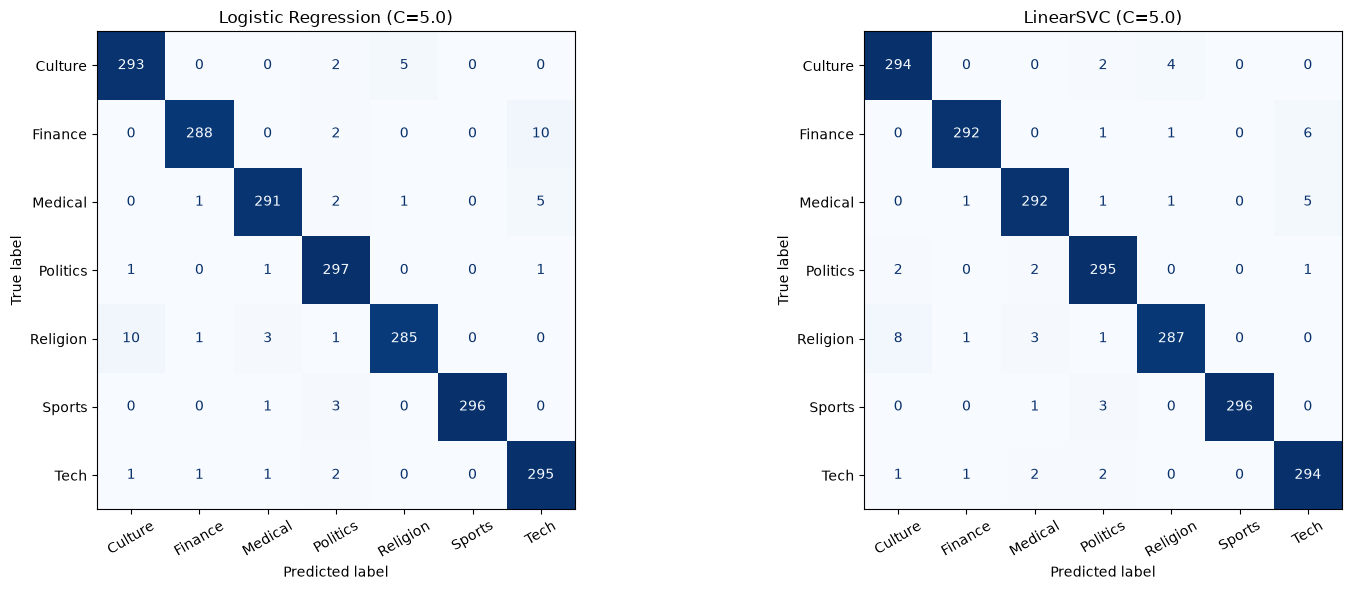

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix

lr_test_preds = best_lr_pipeline.predict(X_test)
svc_test_preds = best_svc_pipeline.predict(X_test)

champion_test_preds = svc_test_preds if winner_key == "svc" else lr_test_preds

final_test_df = pd.DataFrame([
    {
        "Model": f"{lr_label} [Champion]" if winner_key == "lr" else lr_label,
        "Test Accuracy": round(accuracy_score(y_test, lr_test_preds), 4),
        "Test Macro F1": round(f1_score(y_test, lr_test_preds, average="macro"), 4),
        "Test Weighted F1": round(f1_score(y_test, lr_test_preds, average="weighted"), 4),
    },
    {
        "Model": f"{svc_label} [Champion]" if winner_key == "svc" else svc_label,
        "Test Accuracy": round(accuracy_score(y_test, svc_test_preds), 4),
        "Test Macro F1": round(f1_score(y_test, svc_test_preds, average="macro"), 4),
        "Test Weighted F1": round(f1_score(y_test, svc_test_preds, average="weighted"), 4),
    },
])
display(final_test_df)

print(f"\nClassification Report — {lr_label}:")
print(classification_report(y_test, lr_test_preds, digits=4))

print(f"\nClassification Report — {svc_label}:")
print(classification_report(y_test, svc_test_preds, digits=4))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

models_preds = [
    (lr_test_preds, f"Logistic Regression (C={best_lr_c})"),
    (svc_test_preds, f"LinearSVC (C={best_svc_c})"),
]

for ax, (preds, title) in zip(axes, models_preds):
    cm = confusion_matrix(y_test, preds, labels=overall_best_pipeline.classes_)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=overall_best_pipeline.classes_)
    disp.plot(cmap="Blues", ax=ax, values_format="d", xticks_rotation=30, colorbar=False)
    ax.set_title(title)

plt.tight_layout()
figures_dir = PART_C_DIR / "results" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(figures_dir / "part_c_confusion_matrix.png", dpi=300)
plt.show()

In [ ]:
errors_df = pd.DataFrame({
    "text": X_test,
    "true": y_test,
    "pred": champion_test_preds,
})
misclassified = errors_df[errors_df["true"] != errors_df["pred"]].copy()

print(f"Total misclassified: {len(misclassified)} / {len(X_test)} ({len(misclassified) / len(X_test):.2%})")

print("\nErrors per true class:")
print(misclassified["true"].value_counts())

print("\nTop confused class pairs (True -> Predicted):")
pair_counts = misclassified.groupby(["true", "pred"]).size().sort_values(ascending=False)
print(pair_counts.head(5))

top_true, top_pred = pair_counts.index[0]
print(f"\nSample articles for top confusion ({top_true} -> {top_pred}):")
sample_errors = misclassified[(misclassified["true"] == top_true) & (misclassified["pred"] == top_pred)]
for _, row in sample_errors.head(3).iterrows():
    print("-" * 50)
    print(row["text"][:220] + "...")

Total misclassified: 50 / 2100 (2.38%)

Errors per true class:
true
Religion    13
Medical      8
Finance      8
Culture      6
Tech         6
Politics     5
Sports       4
Name: count, dtype: int64

Top confused class pairs (True -> Predicted):
true      pred    
Religion  Culture     8
Finance   Tech        6
Medical   Tech        5
Culture   Religion    4
Religion  Medical     3
dtype: int64

Sample articles for top confusion (Religion -> Culture):
--------------------------------------------------
إعداد: محمد ولد محمد سالم ولد الشاعر الإماراتي حمد بن خليفة أبو شهاب في عام 1932 في «الفريج الوسطي» في إمارة عجمان، وقرأ القرآن عند المطوِّع على غرار أبناء المنطقة آنذاك، ثم التحق بمدرسة (المحمدية) التي تأسست في عجمان وك...
--------------------------------------------------
إعداد: محمد ولد محمد سالمينتمي الكاتب أحمد أمين (1886 - 1954) إلى أدباء ومفكري عصر النهضة العربية الذين حملوا لواء العصرنة والتنوير على مستويات الفكر والأدب والتاريخ، فقد خاض بقلمه السيال في كل تلك المجالات، وكان ذا أس

In [ ]:
import joblib

models_dir = PROJECT_ROOT / "models" / "text"
models_dir.mkdir(parents=True, exist_ok=True)
model_path = models_dir / "arabic_news_pipeline.pkl"

joblib.dump(overall_best_pipeline, model_path)
print(f"Saved champion model ({overall_best_name}) to: {model_path}")

reloaded_pipe = joblib.load(model_path)
sample_text = "حقق المنتخب الوطني فوزا كبيرا في تصفيات كأس العالم بعد أداء رائع في الشوط الثاني"
print("Reload check:", reloaded_pipe.predict([sample_text])[0])

Saved champion model (LinearSVC (TF-IDF (1, 2), C=5.0)) to: F:\Study\Year_3\Machine Learning\Hushhhhh-machine-is-learning\models\text\arabic_news_pipeline.pkl
Reload check: Sports
